# Wykład 6 — Gdzie mieszkają zmienne? Adresy, wskaźniki i pamięć

W W2 poznaliśmy typ i wartość zmiennej, w W4 jej zasięg oraz argumenty funkcji, a w W5 śledziliśmy zmiany stanu programu. Teraz do tego obrazu dołączymy **adres obiektu w pamięci**. Dzięki niemu funkcja będzie mogła dotrzeć do zmiennej utworzonej przez wywołującego.

**Cel:** po każdej instrukcji umieć wskazać, który obiekt się zmienił, jaka jest jego wartość i dokąd prowadzi wskaźnik. Rozróżnimy wartość zmiennej, jej adres, wartość wskaźnika i adres samego wskaźnika.

Pracujemy z pojedynczymi obiektami i funkcjami w C11. Tablice oraz dostęp do ich elementów poznamy w W7; dynamiczna alokacja i pełny układ pamięci procesu pozostają poza tym wykładem.

**Jak pracować:** przed uruchomieniem zapisz przewidywany wynik, po uruchomieniu porównaj go z obserwacją, następnie zmień jedną instrukcję i uzasadnij różnicę. Przy adresach sprawdzaj relacje między obiektami: konkretne liczby mogą zmieniać się między uruchomieniami. Adresy na diagramach są schematyczne.

Rozmiary omawiamy dla demonstracyjnego Linux/x86-64 z GCC: `char` zajmuje 1 B, `int` 4 B, `double` 8 B, a wskaźniki do tych typów po 8 B. To własność naszej platformy; rzeczywiste rozmiary sprawdzamy przez `sizeof`.

## W6.1 — Gdzie mieszkają zmienne?

**Problem:** czy zmienna to tylko nazwa i liczba widoczna w kodzie?

Obiekt jest obszarem pamięci przechowującym wartość. Typ określa sposób interpretacji jego zawartości i rozmiar tego obszaru. Nazwa pozwala odwołać się do obiektu w programie, a adres wskazuje jego położenie. To cztery różne informacje: **nazwa, typ, adres i wartość**.

Pamięć przedstawimy jako kolejne bajty z adresami. Jeden obiekt może zajmować kilka bajtów. Znany z W2 operator `sizeof` podaje rozmiar w bajtach; do wypisania jego wyniku służy format `%zu`.

**Przewidź:** czy zmiana wartości `int` ze 100 na 200 zmieni `sizeof` tego obiektu? Wyjaśnij, dlaczego rozmiar i wartość odpowiadają na inne pytania. Następny krok: jak uzyskać adres takiego obiektu?

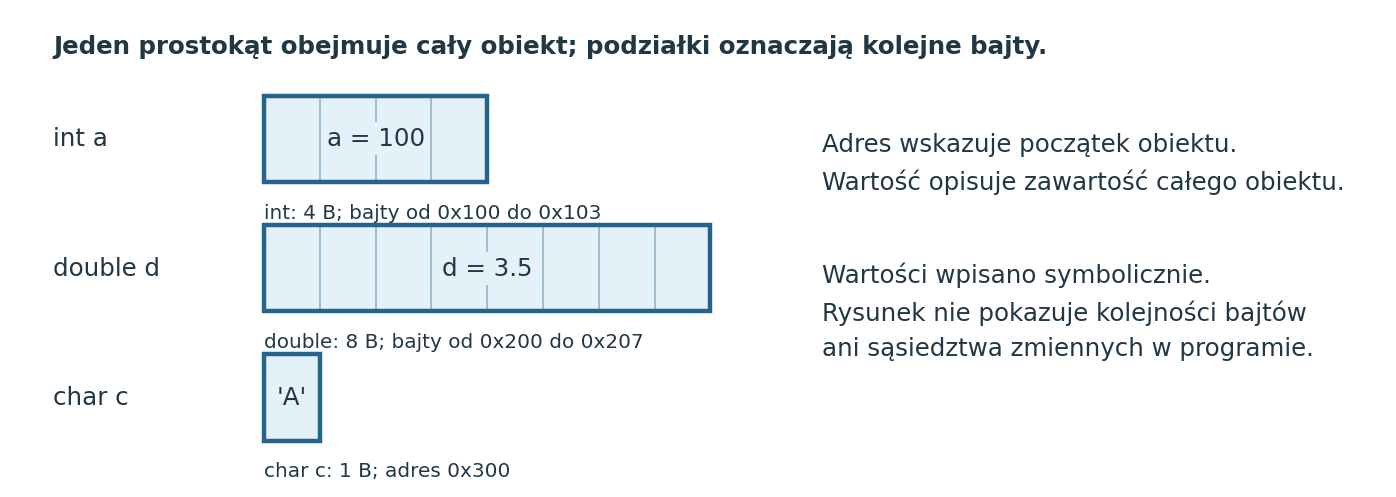

Schemat dla naszej platformy: adresy i rozmiary trzech niezależnych obiektów. Adresy są umowne.

### Ile miejsca zajmuje obiekt?

**Przewidź:** zapisz rozmiary `a`, `d` i `c` w bajtach. Następnie uruchom program i porównaj wydruk z diagramem. Dla tego doświadczenia interesuje nas rozmiar całego obiektu, bez oglądania poszczególnych bajtów.

In [ ]:
#include <stdio.h>

int main(void)
{
    int a = 100;
    double d = 3.5;
    char c = 'A';

    printf("a = %d, rozmiar = %zu B\n", a, sizeof a);
    printf("d = %.1f, rozmiar = %zu B\n", d, sizeof d);
    printf("c = %c, rozmiar = %zu B\n", c, sizeof c);
    return 0;
}

**Interpretacja:** na naszej platformie wydruk obejmuje 4 B dla `a`, 8 B dla `d` i 1 B dla `c`. Liczba 100 jest wartością `a`; liczba 4 opisuje ilość pamięci przeznaczonej na obiekt.

**Zmień:** ustaw `a = 200`, pozostawiając typ `int`. Przed ponownym uruchomieniem wskaż, która część wydruku się zmieni.

**Kontrola:** dlaczego zapisanie mniejszej liczby, np. 1, nie zmniejsza rozmiaru tego samego obiektu `int`? Rozmiar określa typ, a nie liczba cyfr wartości.

## W6.2 — Jak poznać adres?

**Problem:** jak przekazać programowi informację, gdzie znajduje się konkretna zmienna?

Dla `int a = 100` wyrażenie `a` odczytuje liczbę, a `&a` daje adres obiektu `a`. Operator `&` pobiera adres. To ten sam zapis, który pojawił się w W3 w `scanf("%d", &a)`: funkcja potrzebuje miejsca, do którego zapisze odczytaną liczbę.

Adres wypisujemy przez `%p`, przekazując `&a`. Na naszej platformie zwykle zobaczymy zapis szesnastkowy z początkiem `0x`; dokładna postać wydruku zależy od implementacji.

**Sprawdź rozumienie:** po przypisaniu `a = 200` zmienia się zawartość istniejącego obiektu. Czy z tego wynika zmiana jego adresu? Uzyskany adres możemy także przechować w zmiennej odpowiedniego typu.

### Wartość się zmienia, adres pozostaje

**Przewidź:** jakie liczby zostaną wypisane przed i po przypisaniu? Czy oba wydruki adresu tego samego obiektu będą równe? Nie przewiduj konkretnego numeru adresu. Uruchom program i porównaj te dwie relacje.

In [ ]:
#include <stdio.h>

int main(void)
{
    int a = 100;

    printf("Przed: a = %d, &a = %p\n", a, &a);
    a = 200;
    printf("Po:    a = %d, &a = %p\n", a, &a);
    return 0;
}

**Interpretacja:** wartość zmienia się ze 100 na 200, a oba adresy w jednym uruchomieniu są takie same. Przypisanie zapisuje nową liczbę do istniejącego obiektu. Ponowne uruchomienie programu może pokazać inny adres.

**Zmień:** zastąp `a = 200` przez `a = a + 1`. Przewidź nową wartość oraz relację między dwoma adresami, a potem uruchom ponownie.

**Kontrola:** czy zamiast `&a` można przekazać do `scanf("%d", ...)` samą liczbę `a`? Nie: dla `%d` funkcja potrzebuje wskaźnika do obiektu `int`, do którego ma zapisać wynik. Sam odczyt liczby nie określa miejsca zapisu.

## W6.3 — Czym jest wskaźnik?

**Problem:** jak zapamiętać adres i później z niego skorzystać?

Wskaźnik to typ zmiennej przechowującej adres. Zapis `int *p = &a` deklaruje `p` jako wskaźnik do `int` i od razu nadaje mu adres istniejącego obiektu `a`. Gwiazdka w deklaracji opisuje typ; samo utworzenie wskaźnika nie tworzy drugiego obiektu `int`.

`p` również jest obiektem: ma własne miejsce w pamięci, adres `&p` i rozmiar `sizeof p`. Na naszej platformie `int *` i `double *` zajmują po 8 B, choć wskazywane `int` i `double` zajmują odpowiednio 4 B i 8 B. **Rozmiar wskaźnika i rozmiar jego celu to różne wielkości.**

**Przewidź:** które wyrażenia wskazują ten sam obiekt: `p`, `&a`, `&p`? Skoro umiemy zapisać adres, możemy zapytać o zawartość pod tym adresem.

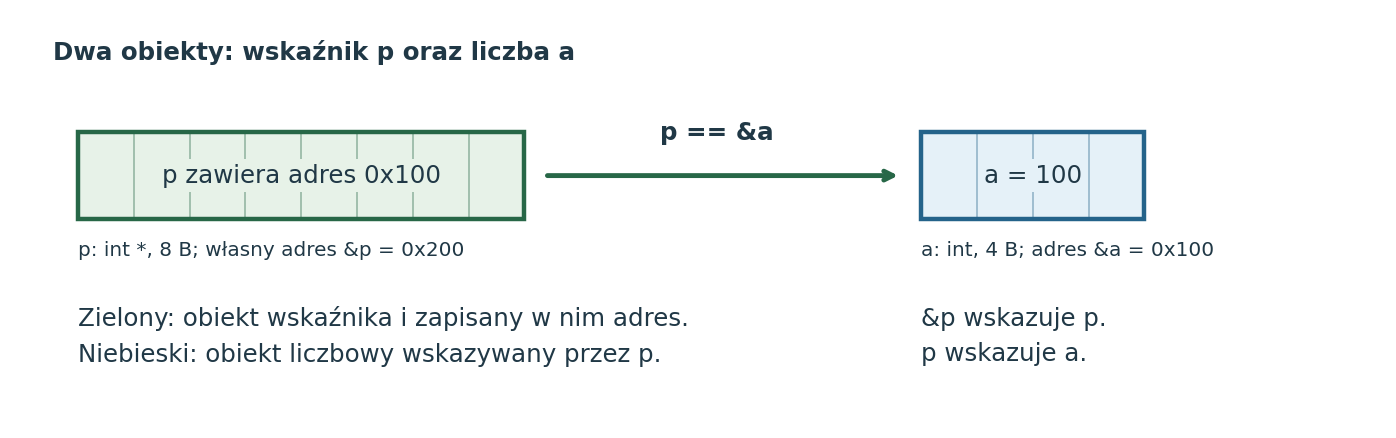

Schemat dla int a = 100; int *p = &a;. Adres wskaźnika &p różni się od przechowywanego w nim adresu p.

### Wskaźnik ma własne miejsce w pamięci

**Przewidź:** które z trzech wydrukowanych adresów będą takie same: `&a`, `p`, `&p`? Jakie rozmiary zobaczysz dla `a`, `d`, `p` i `pd`? Uruchom program i sprawdź osobno zgodność adresów oraz rozmiarów.

In [ ]:
#include <stdio.h>

int main(void)
{
    int a = 100;
    double d = 3.5;
    int *p = &a;
    double *pd = &d;

    printf("&a = %p\n", (void *)&a);
    printf("p  = %p\n", (void *)p);
    printf("&p = %p\n", (void *)&p);
    printf("p == &a: %d\n", p == &a);
    printf("Rozmiar a = %zu B, p = %zu B\n", sizeof a, sizeof p);
    printf("Rozmiar d = %zu B, pd = %zu B\n", sizeof d, sizeof pd);
    return 0;
}

**Interpretacja:** `p` i `&a` opisują ten sam adres, co potwierdza wynik porównania równy 1. `&p` jest adresem osobnego obiektu. Na naszej platformie oba wskaźniki zajmują 8 B, choć obiekty `a` i `d` mają różne rozmiary.

**Zmień:** zastąp początkowe `a = 100` przez `a = -7`. Przewidź, czy relacja `p == &a` i rozmiary się zmienią; sprawdź to ponownym uruchomieniem. Konkretne adresy mogą być inne, lecz relacja pozostanie prawdziwa.

**Kontrola:** czy `int *p = &a` kopiuje do `p` liczbę 100? Nie: kopiuje adres obiektu `a`. Jak zapisać odczyt liczby znajdującej się pod tym adresem? Do tego posłuży dereferencja.

## W6.4 — Co kryje się pod adresem?

**Problem:** jak odczytać wartość obiektu, mając jego adres?

Dla poprawnie zainicjalizowanego `int *p = &a` wyrażenie `*p` oznacza obiekt wskazywany przez `p`; użyte w obliczeniu odczytuje jego wartość. Tę operację nazywamy **dereferencją**. Tutaj `*` jest operatorem w wyrażeniu, a w `int *p` było częścią deklaracji.

Rozdziel cztery zapisy: `p` przechowuje adres `a`, `*p` pozwala dotrzeć do `a`, `&p` jest adresem obiektu wskaźnika, a `&a` jest adresem liczby. Jeśli `p == &a`, odczyty `a` i `*p` dają tę samą wartość.

**Przewidź:** dla `a = 100` i `p = &a` co odczytasz przez `*p` po wykonaniu `a = 20`? Wskaźnik prowadzi do obiektu, więc nie przechowuje kopii jego dawnej liczby.

### Odczyt przez dwa zapisy

**Przewidź:** w pierwszym wydruku porównaj `a` z `*p`, a w drugim `&a` z `p`. Po wykonaniu `a = 20` czy `*p` da starą wartość 100? Uruchom program i wskaż, które wielkości są liczbami, a które adresami.

In [ ]:
#include <stdio.h>

int main(void)
{
    int a = 100;
    int *p = &a;

    printf("a = %d, *p = %d\n", a, *p);
    printf("&a = %p, p = %p, &p = %p\n",
           (void *)&a, (void *)p, (void *)&p);
    a = 20;
    printf("Po a = 20: a = %d, *p = %d\n", a, *p);
    return 0;
}

**Interpretacja:** najpierw `a` i `*p` dają 100, potem oba dają 20. To odczyty tego samego obiektu. Adresy `&a` i `p` są równe; `&p` należy do osobnego obiektu wskaźnika.

**Zmień:** zastąp `a = 20` instrukcją `*p = 20` i odpowiednio zmień opis wydruku. Przewidź obie wypisywane liczby, potem uruchom program.

**Kontrola:** dlaczego zapis przez `*p` jest widoczny jako nowa wartość `a`? Ponieważ obie drogi wskazują ten sam obiekt. Sam adres zapisany w `p` pozostaje bez zmian.

## W6.5 — Czy wskaźnik może zmienić wartość?

**Problem:** czym różni się zmiana celu wskaźnika od zmiany wskazywanej liczby?

Przypisanie `p = &b` zmienia zawartość obiektu `p`: odtąd przechowuje adres `b`. Przypisanie `*p = 20` zapisuje 20 do obiektu, który jest aktualnym celem wskaźnika. Samo przepięcie `p` nie przenosi ani nie zmienia liczb `a` i `b`.

Dwa wskaźniki mogą prowadzić do tego samego obiektu. Jeśli `p` i `q` wskazują `a`, zapis przez `*p` jest widoczny również przy odczycie `*q`. To **aliasowanie**: kilka dróg dostępu do jednego obiektu.

**Przewidź stan pamięci:** zacznij od `a = 100`, `b = 200`, `p = &a`; wykonaj kolejno `*p = 20`, `p = &b`, `*p = 30`. Po każdej instrukcji podaj wartości obu liczb i cel wskaźnika. Za chwilę potraktujemy sam wskaźnik jako taki cel.

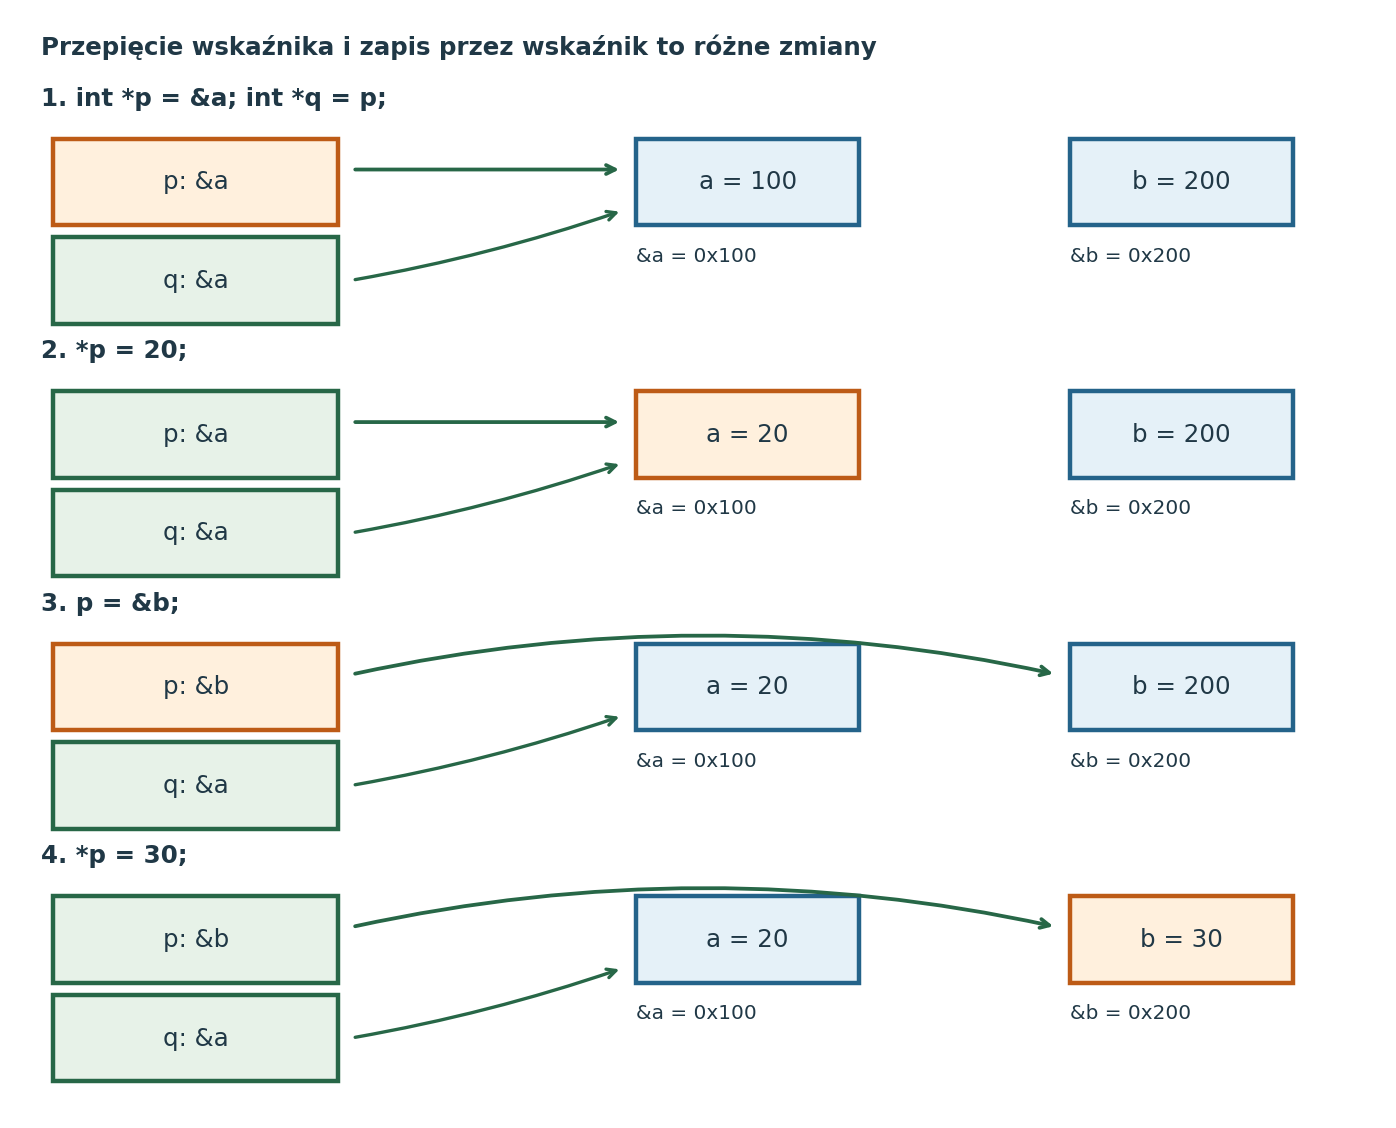

Schemat kolejnych stanów programu. Zielony oznacza wskaźnik, niebieski liczbę, pomarańczowy obiekt właśnie zmieniony. q cały czas wskazuje a; adresy są umowne.

### Jeden obiekt, dwie drogi dostępu

`q = p` kopiuje wartość wskaźnika, więc oba wskaźniki początkowo prowadzą do `a`. **Przewidź:** uzupełnij na kartce wartości `a`, `b`, `*p`, `*q` po każdej instrukcji z diagramu. Następnie uruchom program i porównaj cztery stany.

In [ ]:
#include <stdio.h>

int main(void)
{
    int a = 100;
    int b = 200;
    int *p = &a;
    int *q = p;

    printf("Start:      a=%d b=%d *p=%d *q=%d\n", a, b, *p, *q);
    *p = 20;
    printf("*p = 20:    a=%d b=%d *p=%d *q=%d\n", a, b, *p, *q);
    p = &b;
    printf("p = &b:     a=%d b=%d *p=%d *q=%d\n", a, b, *p, *q);
    *p = 30;
    printf("*p = 30:    a=%d b=%d *p=%d *q=%d\n", a, b, *p, *q);
    printf("p == &b: %d, q == &a: %d\n", p == &b, q == &a);
    return 0;
}

**Interpretacja:**

| Po instrukcji | `a` | `b` | `*p` | `*q` |
|:--|--:|--:|--:|--:|
| Inicjalizacja | 100 | 200 | 100 | 100 |
| `*p = 20` | 20 | 200 | 20 | 20 |
| `p = &b` | 20 | 200 | 200 | 20 |
| `*p = 30` | 20 | 30 | 30 | 20 |

Przepięcie `p` nie przepina `q`: to dwie osobne zmienne, które początkowo przechowywały taki sam adres. Zmiana `a` jest jednak widoczna przez każdą drogę prowadzącą do `a`.

**Zmień:** w ostatnim zapisie zastąp `*p = 30` przez `*q = 30`; popraw także opis wydruku. Przewidź stan końcowy. Po uruchomieniu powinno być `a=30`, `b=200`, `*p=200`, `*q=30`.

**Kontrola:** która instrukcja zmienia adres zapisany we wskaźniku, a która liczbę pod tym adresem? Porównaj lewe strony `p = ...` i `*p = ...`.

## W6.6 — Czy wskaźnik też ma adres?

**Problem:** skoro `p` jest zmienną, czy inny wskaźnik może wskazywać właśnie ją?

Tak: dla `int *p = &a` deklaracja `int **pp = &p` tworzy wskaźnik do wskaźnika do `int`. Wartością `pp` jest adres `p`. Jedna dereferencja, `*pp`, dociera do obiektu `p`; druga, `**pp`, dociera do liczby `a`.

Czytaj tę relację krok po kroku: **`pp` → `p` → `a`**. Każda strzałka wymaga poprawnego wskaźnika do żyjącego obiektu. Dwa znaki `*` opisują dwa kolejne kroki, nie mnożenie.

**Sprawdź rozumienie:** który zapis zmieni liczbę `a`: `**pp = 20` czy `*pp = &b`? Który przepnie `p`? Umiejętność śledzenia strzałek wymaga także rozpoznawania, kiedy nie wolno za nimi podążyć.

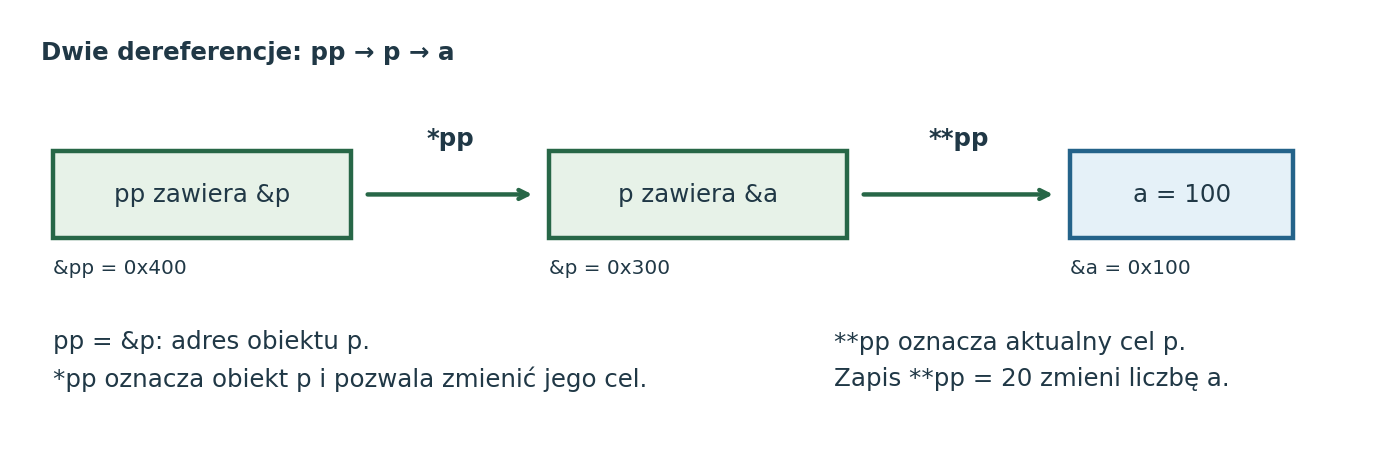

Stan początkowy: int a = 100; int *p = &a; int **pp = &p;. Wszystkie trzy prostokąty oznaczają osobne obiekty. Adresy są umowne.

### Zmieniamy liczbę, potem cel wskaźnika

**Przewidź:** dla `pp = &p` wykonamy `**pp = 20`, następnie `*pp = &b`, a na końcu `**pp = 30`. Kiedy zmieni się `a`, kiedy `b`, a kiedy sam `p`? Uruchom program i prześledź każdą dereferencję osobno.

In [ ]:
#include <stdio.h>

int main(void)
{
    int a = 100;
    int b = 200;
    int *p = &a;
    int **pp = &p;

    printf("pp = %p, &p = %p\n", (void *)pp, (void *)&p);
    printf("*pp = %p, p = %p\n", (void *)*pp, (void *)p);
    printf("Start:       a=%d b=%d **pp=%d\n", a, b, **pp);
    **pp = 20;
    printf("**pp = 20:   a=%d b=%d **pp=%d\n", a, b, **pp);
    *pp = &b;
    printf("*pp = &b:    a=%d b=%d **pp=%d\n", a, b, **pp);
    **pp = 30;
    printf("**pp = 30:   a=%d b=%d **pp=%d\n", a, b, **pp);
    printf("p == &b: %d, pp == &p: %d\n", p == &b, pp == &p);
    return 0;
}

**Interpretacja:** `pp` i `&p` są równe, podobnie jak `*pp` i `p`. Pierwszy zapis liczby daje `a=20`, `b=200`. Instrukcja `*pp = &b` zmienia obiekt `p`; obie liczby pozostają bez zmian, a odczyt `**pp` daje odtąd 200. Ostatni zapis daje `a=20`, `b=30`. Sam `pp` nadal wskazuje ten sam obiekt `p`.

**Zmień:** zamień `*pp = &b` na `*pp = &a` i popraw opis wydruku. Przewidź, do którego obiektu trafi końcowe 30. Po uruchomieniu sprawdź `a=30`, `b=200`; końcowe porównanie `p == &b` będzie fałszywe.

**Kontrola:** rozpisz `**pp` jako `*(*pp)`. Pierwsza dereferencja dociera do wskaźnika `p`, druga podąża za jego aktualną wartością. Czy po przepięciu `p` trzeba zmienić `pp`, aby nadal wskazywał `p`? Nie: obiekt wskaźnika pozostał w tym samym miejscu.

## W6.7 — Kiedy wskaźnik jest niebezpieczny?

**Problem:** czy każda zmienna typu wskaźnikowego pozwala bezpiecznie odczytać `*p`?

Przed dereferencją potrzebny jest wskaźnik do odpowiedniego, istniejącego obiektu, z prawem do zamierzonego odczytu lub zapisu. Niezainicjalizowany lokalny wskaźnik nie ma ustalonego poprawnego celu. `NULL` jawnie oznacza brak celu; wolno to sprawdzić, lecz nie wolno dereferencjonować takiego wskaźnika.

Z W4 pamiętamy czas życia obiektu. Po wyjściu z bloku zwykła zmienna lokalna tego bloku przestaje istnieć. Zachowany wcześniej adres nie przedłuża jej życia. Sam warunek `p != NULL` również nie dowodzi, że cel nadal istnieje, a rzutowanie typu nie naprawia błędnego adresu.

**Kontrola:** czy wskaźnik może być różny od `NULL` i nadal nie nadawać się do dereferencji? Uzasadnij odpowiedź czasem życia celu. Niebezpieczne fragmenty analizujemy bez ich wykonywania. Poprawne wskaźniki wykorzystamy teraz do komunikacji z funkcją.

### Brak celu można sprawdzić

`NULL` jest dostępne po dołączeniu `<stdio.h>`. **Przewidź:** czy pierwszy warunek pozwoli odczytać `*p`? Co zmieni późniejsze `p = &a`? Uruchom program i wskaż, dlaczego obie wykonane dereferencje są poprawne: w tym miejscu `p` wskazuje żyjący, zainicjalizowany obiekt `int`.

Warunek w tym przykładzie obsługuje świadomie ustawiony brak celu. Nie jest ogólnym testem poprawności dowolnego adresu.

In [ ]:
#include <stdio.h>

int main(void)
{
    int a = 10;
    int *p = NULL;

    if (p != NULL) {
        printf("*p = %d\n", *p);
    } else {
        puts("Brak celu: nie odczytujemy *p.");
    }

    p = &a;
    if (p != NULL) {
        printf("Po p = &a: *p = %d\n", *p);
        *p = 20;
    }
    printf("Po zapisie: a = %d\n", a);
    return 0;
}

**Interpretacja:** pierwszy warunek jest fałszywy i program wypisuje komunikat o braku celu. Po przypisaniu `p = &a` odczyt daje 10, a zapis ustawia `a` na 20. Poprawność wynika z tego, skąd pochodzi adres i że obiekt `a` nadal istnieje.

**Zmień:** zainicjalizuj `p` od razu przez `&a` zamiast `NULL`. Przewidź pierwszy komunikat; po uruchomieniu powinien pojawić się dodatkowy odczyt `*p = 10`, bez komunikatu o braku celu.

**Kontrola:** czy ustawienie wskaźnika na `NULL` usuwa jego dawny cel? Nie: zmienia tylko wartość wskaźnika. Czy sprawdzenie niezainicjalizowanego wskaźnika przez `p != NULL` rozwiązuje problem? Nie: najpierw trzeba nadać mu określoną wartość.

### Rozpoznaj błąd przed uruchomieniem

**Poniższe fragmenty służą wyłącznie do analizy. Nie uruchamiaj ich.** Każdy przedstawia inną przyczynę, dla której zapis przez wskaźnik jest niepoprawny.

**1. Nieustalony cel:** lokalny wskaźnik nie został zainicjalizowany.

```C
int *p;
*p = 20;  /* brak ustalonego, poprawnego adresu */
```

Naprawa: nadaj wskaźnikowi adres właściwego obiektu przed użyciem albo ustaw `NULL` i obsłuż brak celu.

**2. Jawny brak celu:** `NULL` można przechować i sprawdzić, lecz nie dereferencjonować.

```c
int *p = NULL;
*p = 20;  /* NULL nie wskazuje obiektu */
```

Naprawa: ustal prawidłowy cel albo pomiń operację, gdy celu nie ma. Samo rzutowanie `(int *)` nie tworzy obiektu i nie naprawia adresu.

**3. Cel już nie istnieje:** adres nie przedłuża czasu życia zwykłej zmiennej lokalnej.

```c
int *p = NULL;
{
    int a = 10;
    p = &a;
}
*p = 20;  /* czas życia a zakończył się przy wyjściu z bloku */
```

Naprawa: wykonaj potrzebne operacje w czasie życia celu. Można ustawić `p = NULL` jeszcze przed opuszczeniem tego bloku, aby później jawnie reprezentował brak celu. Nie sprawdzaj ani nie dereferencjonuj zachowanego adresu po zakończeniu życia obiektu. Jeśli inne wskaźniki też prowadziły do `a`, zmiana samego `p` ich nie naprawi.

**Samokontrola:** wyjaśnij błąd w każdym fragmencie bez przewidywania wydruku ani rodzaju awarii. Niepoprawna dereferencja oznacza działanie niezdefiniowane: język nie gwarantuje ani wyniku, ani zatrzymania programu. Dla poprawnego użycia sprawdź inicjalizację wskaźnika, rzeczywisty typ i czas życia celu oraz możliwość zamierzonego odczytu lub zapisu. Przy odczycie potrzebna jest także ustalona wartość wskazanego obiektu.

## W6.8 — Co przekazujemy funkcji?

**Problem:** dlaczego funkcja zmieniająca parametr `int` nie zmienia liczby w `main`, a funkcja z parametrem `int *` może to zrobić?

W C **wszystkie argumenty są przekazywane przez wartość**, również wskaźniki. Funkcja z parametrem `int a` otrzymuje kopię liczby. Funkcja z parametrem `int *p` otrzymuje kopię adresu; przez `*p` może dotrzeć do oryginalnego obiektu wywołującego.

Zmiana lokalnego parametru `p` i zapis do `*p` dotyczą różnych obiektów. To wyjaśnia także znane z W3 `scanf`: przekazanie `&a` umożliwia funkcji zapis do `a`, choć sam adres nadal jest kopiowaną wartością argumentu.

**Przewidź:** co pozostanie w zmiennej wywołującego po zmianie kopii liczby, a co po zapisie przez kopię jej adresu? Ten sam mechanizm pozwoli umieścić wyniki funkcji w kilku wskazanych miejscach.

### Kopia liczby i kopia adresu

Każde wywołanie tworzy własne parametry lokalne. **Przewidź:** zapisz wartość `a` po każdym z trzech wywołań. Czy `p` w `main` nadal będzie wskazywał `a`, gdy `przepnij_kopie` przypisze do swojego parametru inny adres?

Uruchom program, rozdzielając trzy obiekty: liczbę `a` w `main`, wskaźnik `p` w `main` i lokalny parametr każdej funkcji. Funkcje mają różne nazwy; C nie wybiera wersji tej samej funkcji na podstawie typu argumentu.

In [ ]:
#include <stdio.h>

void zmien_kopie(int a)
{
    a = 500;
    printf("W zmien_kopie: a=%d\n", a);
}

void zmien_cel(int *p)
{
    *p = 500;
    printf("W zmien_cel: *p=%d\n", *p);
}

void przepnij_kopie(int *p)
{
    int lokalna = 300;
    p = &lokalna;
    printf("W przepnij_kopie: *p=%d\n", *p);
}

int main(void)
{
    int a = 9;
    int *p = &a;

    zmien_kopie(a);
    printf("Po zmien_kopie: a=%d\n", a);
    zmien_cel(p);
    printf("Po zmien_cel: a=%d\n", a);
    przepnij_kopie(p);
    printf("Po przepnij_kopie: a=%d *p=%d p==&a: %d\n",
           a, *p, p == &a);
    return 0;
}

**Interpretacja:**

| Wywołanie | Co jest kopiowane do parametru? | Co zmienia funkcja? | `a` po powrocie |
|:--|:--|:--|--:|
| `zmien_kopie(a)` | Liczba 9 | Lokalny parametr `a` | 9 |
| `zmien_cel(p)` | Adres `a` | Oryginalny obiekt przez `*p` | 500 |
| `przepnij_kopie(p)` | Adres `a` | Lokalny parametr wskaźnikowy `p` | 500 |

W ostatniej funkcji odczyt 300 odbywa się jeszcze w czasie życia `lokalna`. Jej adres nie trafia do wskaźnika w `main` i nie jest zwracany. Po powrocie wskaźnik w `main` nadal prowadzi do `a`: wydruk to `a=500 *p=500 p==&a: 1`.

**Zmień:** pomiń wywołanie `zmien_cel(p)`. Przewidź wynik końcowy, następnie uruchom program: `a` i `*p` pozostaną równe 9. Przepięcie kopii wskaźnika nadal ich nie zmieni.

**Kontrola:** czy zastąpienie `zmien_cel(p)` przez `zmien_cel(&a)` da inny efekt? Nie: w tym miejscu oba argumenty mają tę samą wartość adresu. Funkcja otrzymuje kopię tego adresu, tak jak `scanf` otrzymuje adres miejsca zapisu. W C nie powstał osobny mechanizm przekazywania przez referencję.

## W6.9 — Jak uzyskać więcej niż jeden wynik?

**Problem:** jak przekazać z funkcji dwie obliczone liczby bez zmiennych globalnych?

Funkcja może zapisać wyniki do obiektów wywołującego przez **parametry wyjściowe**, czyli parametry wskaźnikowe przeznaczone do zapisu. Dwa adresy pozwalają wskazać dwa osobne miejsca na wyniki. Innym zastosowaniem jest `swap(&a, &b)`: funkcja zamienia wartości dwóch istniejących obiektów, korzystając ze zmiennej tymczasowej.

`return x, y;` nie zwraca dwóch wartości. Operator przecinka oblicza lewy operand, następnie prawy, a wartością całego wyrażenia jest wartość prawego operandu. Do uzyskania dwóch wyników użyjemy dwóch parametrów wyjściowych.

**Sprawdź rozumienie:** dlaczego przekazanie samych liczb `a` i `b` do funkcji zamieniającej jej lokalne kopie nie wystarczy? Wskaż, do jakich obiektów muszą prowadzić parametry poprawnego `swap`.

### Dwa miejsca na dwa wyniki

Funkcja `suma_roznica` otrzymuje dwie liczby wejściowe oraz adresy dwóch osobnych obiektów wynikowych. Zakładamy, że suma i różnica mieszczą się w `int`, a oba adresy wskazują żyjące obiekty `int` dostępne do zapisu.

**Przewidź:** co znajdzie się w `suma` i `roznica` po wywołaniu dla 8 i 3? Uruchom program i wskaż każdą drogę zapisu: `ps` → `suma`, `pr` → `roznica`.

In [ ]:
#include <stdio.h>

void suma_roznica(int x, int y, int *ps, int *pr)
{
    *ps = x + y;
    *pr = x - y;
}

int main(void)
{
    int suma = 0;
    int roznica = 0;

    suma_roznica(8, 3, &suma, &roznica);
    printf("suma=%d roznica=%d\n", suma, roznica);
    return 0;
}

**Interpretacja:** wynik to `suma=11 roznica=5`. Funkcja o typie wyniku `void` nie zwraca liczby przez `return`; zapisuje dwie liczby do wskazanych obiektów. Parametry `ps` i `pr` nadal są lokalnymi kopiami adresów.

**Zmień:** odwróć kolejność liczb wejściowych: `suma_roznica(3, 8, &suma, &roznica)`. Przewidź znak różnicy. Po uruchomieniu otrzymasz `suma=11 roznica=-5`.

**Kontrola:** dlaczego wskazaliśmy dwa osobne obiekty wynikowe? Gdy oba parametry wyjściowe prowadzą do jednego obiektu, drugi zapis nadpisze pierwszy i nie zachowamy dwóch wyników.

### Dlaczego `return x, y;` nie wystarczy?

Fragment do analizy, a nie osobny program do uruchomienia:

```c
return x, y;
```

To `return (x, y);`. Operator przecinka oblicza najpierw `x`, potem `y`, a wartością całego wyrażenia jest wartość `y`. Dla `x=11`, `y=5` funkcja zwróciłaby tylko 5. Przecinki oddzielające argumenty w wywołaniu `suma_roznica(8, 3, &suma, &roznica)` pełnią inną rolę składniową.

**Kontrola:** ile wartości oddaje tu pojedynczy `return`? Jakie dwa obiekty zachowują wyniki w działającym przykładzie?

### Zamiana dwóch wartości

`swap` otrzymuje adresy obiektów, których wartości ma zamienić. Zmienna `tmp` zachowuje pierwszą liczbę, zanim zostanie ona nadpisana. Oba wskaźniki muszą prowadzić do żyjących obiektów `int`, które wolno odczytywać i zapisywać.

**Przewidź:** podaj kolejno wartości `tmp`, `*pa` i `*pb` po każdej z trzech instrukcji funkcji. Uruchom program: jakie będą `a` i `b` po powrocie?

In [ ]:
#include <stdio.h>

void swap(int *pa, int *pb)
{
    int tmp = *pa;
    *pa = *pb;
    *pb = tmp;
}

int main(void)
{
    int a = 3;
    int b = 8;

    printf("Przed: a=%d b=%d\n", a, b);
    swap(&a, &b);
    printf("Po:    a=%d b=%d\n", a, b);
    return 0;
}

**Interpretacja:** po zachowaniu `tmp=3` pierwszy zapis daje `a=8`, `b=8`. Ostatni zapis odtwarza zachowaną liczbę w `b`: wynik to `a=8`, `b=3`. Bez `tmp` po pierwszym nadpisaniu utracilibyśmy pierwotną wartość `a`.

**Zmień:** dodaj drugie `swap(&a, &b)` i kolejny wydruk. Przed uruchomieniem przewidź stan po dwóch zamianach: wrócimy do `a=3`, `b=8`.

**Kontrola:** co stanie się dla `swap(&a, &a)`? Prześledź instrukcje: wszystkie odczyty i zapisy dotyczą tego samego obiektu, więc jego wartość się nie zmieni. Porównaj to z dwoma parametrami wyjściowymi, które miały zachować dwa różne wyniki.

## W6.10 — Co oznacza `p + 1`?

**Problem:** czy dodanie jedynki do wskaźnika zawsze przesuwa adres o jeden bajt?

Krok arytmetyki wskaźnika zależy od wskazywanego typu. Dla wskaźnika do pojedynczego obiektu wolno utworzyć wskaźnik **jeden za obiektem** przez `p + 1`. Nie wolno go dereferencjonować: za tym obiektem nie uzyskaliśmy nowego obiektu do odczytu lub zapisu.

Na naszej platformie krok dla `char *`, `int *` i `double *` odpowiada odpowiednio 1, 4 i 8 bajtom, czyli 8, 32 i 64 bitom pamięci. Każdy przypadek rozpatrujemy dla osobnej, poprawnie utworzonej zmiennej. Nie wyciągamy wniosków o kolejności niezależnych zmiennych w pamięci.

**Przewidź:** czy jednakowy rozmiar dwóch wskaźników oznacza jednakowy krok ich arytmetyki? Oddziel rozmiar wskaźnika od rozmiaru wskazywanego typu. Co się stanie, gdy sam typ celu nie jest podany?

### Trzy typy, trzy rozmiary kroku

**Przewidź:** jak zmieni się adres po dodaniu 1 do każdego wskaźnika? Uruchom program i porównaj każdą parę adresów osobno. Wielkość kroku w bajtach odczytasz również z wydruku `sizeof` danego obiektu. Przykładowo adres szesnastkowy kończący się na `0x...a0` po kroku 4 B kończyłby się na `0x...a4`.

Każdy `p + 1` oznacza tutaj granicę za jednym obiektem, a nie miejsce udostępnione do dereferencji. Nie porównujemy położenia różnych zmiennych ani nie odejmujemy niespokrewnionych wskaźników.

In [ ]:
#include <stdio.h>

int main(void)
{
    char c = 'A';
    int a = 10;
    double d = 3.5;
    char *pc = &c;
    int *pi = &a;
    double *pd = &d;

    printf("char:   p=%p, p+1=%p, krok=%zu B\n",
           (void *)pc, (void *)(pc + 1), sizeof c);
    printf("int:    p=%p, p+1=%p, krok=%zu B\n",
           (void *)pi, (void *)(pi + 1), sizeof a);
    printf("double: p=%p, p+1=%p, krok=%zu B\n",
           (void *)pd, (void *)(pd + 1), sizeof d);
    printf("Wartosci bez zmian: c=%c a=%d d=%.1f\n", c, a, d);
    return 0;
}

**Interpretacja:** na demonstracyjnej platformie różnice w każdej parze adresów odpowiadają 1 B, 4 B i 8 B, czyli 8, 32 i 64 bitom pamięci. Arytmetyka wskaźnika skaluje krok rozmiarem wskazywanego typu. Wszystkie wartości obiektów pozostały bez zmian.

**Zmień:** w pierwszym wydruku zastąp `pc + 1` przez `pc` i zmień podpis `p+1` na `p`. Przewidź relację adresów: w tym wierszu będą równe, a pozostałe wiersze zachowają swoje kroki. Nie zmieniaj doświadczenia na `pi + 2`: dla tego pojedynczego obiektu taki krok wychodzi poza dozwolony zakres.

**Kontrola:** czy odczyt `*(pi + 1)` byłby legalnym sposobem poznania sąsiedniej zmiennej? Nie: wskaźnik jeden za obiektem wolno utworzyć, ale nie dereferencjonować. Od takiego wskaźnika można natomiast odjąć 1, aby wrócić do pierwotnego obiektu.

## W6.11 — Po co `void *`?

**Problem:** jak przechować adres obiektu bez określania w typie wskaźnika, czy jest to `int`, czy `double`?

`void *` jest ogólnym wskaźnikiem do obiektu. Zapis `void *p = &a` zachowuje adres, ale nie dostarcza typu potrzebnego do odczytu wartości. Jeśli `a` jest żyjącym obiektem `int`, zapis `*(int *)p` przywraca właściwy typ wskaźnika i pozwala odczytać ten obiekt.

Rzutowanie musi odpowiadać rzeczywistemu obiektowi. Nie daje prawa do odczytywania dowolnych bajtów jako dowolnego typu. W standardowym C nie wykonujemy arytmetyki na `void *`, ponieważ `void` nie określa rozmiaru celu.

**Kontrola:** skąd wiadomo, że w danym przykładzie właściwym rzutowaniem jest `(int *)`, a nie `(double *)`? To rzeczywisty obiekt wyznacza legalny dostęp. Sprawdzimy teraz, dlaczego podobna wielkość obszaru pamięci nie usuwa tej zasady.

### Ten sam adres, jawnie przywrócony typ

**Przewidź:** dla `a=4449` i `void *p = &a` jaką wartość da `*(int *)p`? Czy samo przechowanie adresu w `void *` zmienia `a`? Uruchom program i porównaj oba wydrukowane adresy oraz oba odczyty liczby.

In [ ]:
#include <stdio.h>

int main(void)
{
    int a = 4449;
    void *p = &a;

    printf("&a = %p, p = %p\n", (void *)&a, p);
    printf("a = %d, odczyt przez p = %d\n", a, *(int *)p);
    *(int *)p = 20;
    printf("Po zapisie: a = %d\n", a);
    return 0;
}

**Interpretacja:** adresy są takie same, oba odczyty dają 4449, a końcowy zapis ustawia `a` na 20. Wiemy, że `(int *)` jest właściwe, ponieważ adres pochodzi od rzeczywistego obiektu `int`. Dla argumentu `p` przy `%p` dodatkowe rzutowanie nie jest potrzebne: ma on już typ `void *`.

**Zmień:** zastąp odczyt `*(int *)p` przez odczyt `a`. Przewidź, czy zmieni się wynik. Następnie wyjaśnij, dlaczego obie drogi docierają do tej samej liczby.

**Kontrola:** czy można podmienić rzutowanie na `(double *)`, bo adres pozostaje ten sam? Nie. Dostęp musi odpowiadać rzeczywistemu obiektowi, a adres musi także spełniać wymagania wyrównania danego typu. Kompilator zapewnia odpowiednie wyrównanie zadeklarowanemu obiektowi `int`; nie oznacza to istnienia pod tym adresem obiektu innego typu. Rzutowanie nie nadaje takich uprawnień. Standard C nie definiuje także kroku `p + 1` dla `void *`.

## W6.12 — Czy w `double` zmieszczą się dwa `int`?

**Problem:** skoro `double` zajmuje 8 B, a `int` 4 B, czy ten sam obszar może pomieścić bajty dwóch liczb całkowitych?

Na naszej platformie wielkości się zgadzają: 8 B = 2 × 4 B. To porównanie rozmiarów reprezentacji, a nie zgoda na zapisywanie do obiektu `double` przez `int *`. Rzutowanie adresu `double` na `int *` i zapis kolejnych liczb tą drogą narusza reguły dostępu do obiektów w C.

Poprawny eksperyment kopiuje reprezentacje dwóch `int` funkcją `memcpy` do bufora bajtów, po sprawdzeniu rozmiarów. Bajty można skopiować do obiektu `double` i z powrotem do obiektów `int`. Nie odczytujemy tak uzyskanej zawartości jako wartości `double`: dowolne skopiowane bajty nie muszą tworzyć poprawnej reprezentacji tego typu.

**Przewidź:** czy zachowanie wszystkich bajtów wystarcza do odzyskania pierwotnych liczb `int`? Dlaczego nie pozwala przewidzieć liczbowej wartości `double`? Rozmiar opisuje ilość miejsca, a typ wyznacza znaczenie i zasady użycia zawartości.

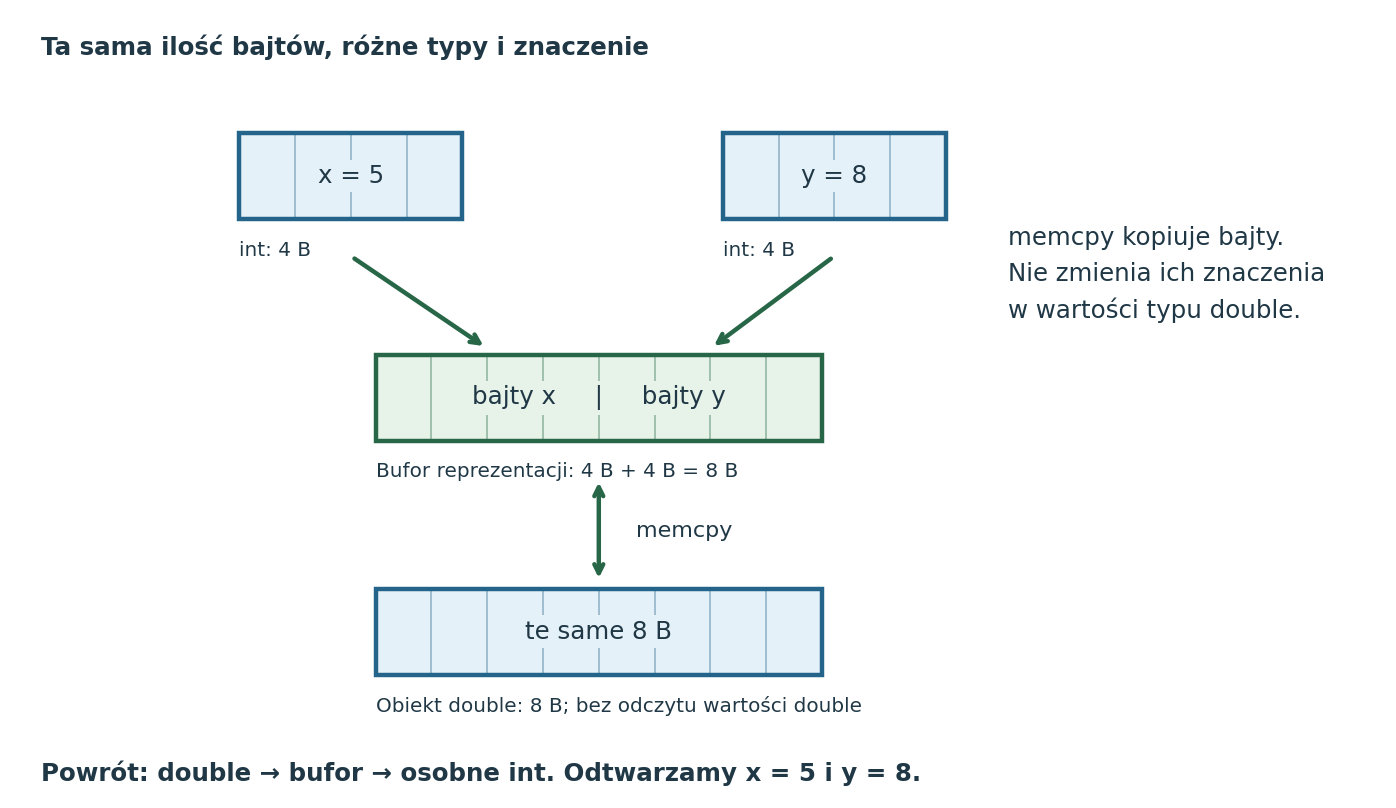

Reprezentacja dwóch int mieści się w 8 B na naszej platformie. Podziałki oznaczają bajty; nie pokazujemy ich wartości ani kolejności wewnątrz int.

### Dwa znaczenia słowa „zmieścić”

Mamy `x=5`, `y=8` oraz obiekt `double d`. **Przewidź:** czy po skopiowaniu reprezentacji obu `int` do 8 B i odzyskaniu tych samych bajtów dostaniemy z powrotem 5 i 8? A czy z równania rozmiarów wynika jakakolwiek konkretna liczba typu `double`?

Kusząca, lecz niepoprawna droga — **fragment koncepcyjny do analizy, nie uruchamiaj**:

```C
int *p = (int *)&d;
*p = 5;
*(p + 1) = 8;
```

Rzutowanie nie zmienia obiektu `double` w dwa obiekty `int`. Zapis przez `int *` narusza reguły dostępu do tego obiektu, a `p + 1` nie upoważnia do traktowania go jak dwóch kolejnych liczb całkowitych. Sam zgodny rozmiar ani ewentualnie odpowiednie wyrównanie nie wystarczają.

W poprawnym doświadczeniu użyjemy `memcpy` z `<string.h>`. Funkcja dostaje miejsce docelowe, źródło i liczbę bajtów do skopiowania. `unsigned char bufor[...]` tworzy wyłącznie techniczny bufor reprezentacji: wielkość w nawiasach określa ilość miejsca. Nie potrzebujemy dostępu do elementów ani pętli. `bufor + sizeof x` wskazuje początek drugiej części, bezpośrednio za bajtami `x`.

Uruchom program i prześledź kopie: **`x`, `y` → bufor → `d` → bufor → `odzyskane_x`, `odzyskane_y`**. Warunek rozmiarów ogranicza ten konkretny pokaz do platformy z `int` 4 B i `double` 8 B.

In [ ]:
#include <stdio.h>
#include <string.h>

int main(void)
{
    int x = 5;
    int y = 8;
    double d = 9.0;
    unsigned char bufor[sizeof x + sizeof y];
    int odzyskane_x = 0;
    int odzyskane_y = 0;

    printf("int: %zu B, double: %zu B, dwie reprezentacje int: %zu B\n",
           sizeof x, sizeof d, sizeof x + sizeof y);
    if (sizeof(int) != 4 || sizeof(double) != 8 ||
        sizeof d != sizeof x + sizeof y) {
        puts("Ten pokaz wymaga int 4 B i double 8 B.");
        return 0;
    }

    printf("Przed kopiowaniem: x=%d y=%d d=%.1f\n", x, y, d);
    memcpy(bufor, &x, sizeof x);
    memcpy(bufor + sizeof x, &y, sizeof y);
    memcpy(&d, bufor, sizeof d);
    puts("Skopiowano 8 B do d; nie odczytujemy wartosci double.");

    memcpy(bufor, &d, sizeof d);
    memcpy(&odzyskane_x, bufor, sizeof odzyskane_x);
    memcpy(&odzyskane_y, bufor + sizeof x, sizeof odzyskane_y);
    printf("Odzyskane: x=%d y=%d\n", odzyskane_x, odzyskane_y);
    printf("Zgodnosc: %d\n", odzyskane_x == x && odzyskane_y == y);
    return (odzyskane_x == x && odzyskane_y == y) ? 0 : 1;
}

**Interpretacja:** rozmiary potwierdzają 4 B + 4 B = 8 B. Początkowe `d=9.0` jest zwykłą liczbą przed podmianą bajtów. Po podmianie kopiujemy wyłącznie reprezentację: nie wypisujemy ani nie używamy `d` jako liczby. Dowolne bajty mogą nie tworzyć poprawnej reprezentacji `double`; nie należy obliczać ich wartości zmiennoprzecinkowej.

Odzyskane liczby to `x=5`, `y=8`, a zgodność wynosi 1. Nie potrzebujemy założenia o kolejności bajtów: kopie wracają do właściwych obiektów `int` w tej samej kolejności, w jakiej trafiły do bufora. Każdy obiekt ma wyrównanie właściwe swojemu typowi; `memcpy` przenosi bajty bez odczytywania obiektu `double` przez `int *`.

**Zmień:** ustaw `x=-3`, `y=42`. Przed uruchomieniem przewidź odzyskane liczby i wynik zgodności. Powinny wynieść odpowiednio −3, 42 i 1; nie przewidujemy nowej wartości `double`.

**Kontrola:** co wykazaliśmy? Reprezentacje dwóch liczb `int` mogą na tej platformie zająć tyle samo miejsca co `double`, a zachowanie bajtów pozwala odzyskać liczby. Nie wykazaliśmy, że `double` jest parą liczb całkowitych ani że wolno zapisywać do niego przez dowolny wskaźnik.

## W6.13 — Sprawdź, co rozumiesz

Prześledź stan pamięci, zanim odczytasz wyniki programu. Dla każdej instrukcji nazwij zmieniany obiekt i odróżnij jego wartość od adresu.

1. `a = 10`, `b = 20`, `p = &a`. Jakie będą `a`, `b` i `*p` po `p = &b; *p = 30;`?
2. `p = &a`, `q = p`. Czy późniejsze `p = &b` przepnie także `q`? Uzasadnij odpowiedź kopiowaniem wartości wskaźnika.
3. `pp = &p`. Do którego obiektu docierasz przez `*pp`, a do którego przez `**pp`?
4. Dlaczego wolno utworzyć `&a + 1`, ale nie odczytać `*(&a + 1)`?
5. Co sprawdzasz przed dereferencją poza warunkiem różnym od `NULL`?

**Samodzielne zadanie:** napisz funkcję, która dla dwóch podanych liczb `int` zapisze mniejszą i większą do dwóch osobnych obiektów przez wskaźniki. Sprawdź pary `(3, 8)`, `(8, 3)`, `(5, 5)` i `(-2, -7)`. Następnie zmień kolejność argumentów i wyjaśnij, dlaczego wyniki nadal powinny opisywać tę samą parę liczb.

Umiesz teraz rozdzielić obiekt, jego adres i prowadzący do niego wskaźnik. Zapis przez poprawny wskaźnik zmienia wskazany obiekt, a przekazanie adresu funkcji nadal oznacza przekazanie argumentu przez wartość. W W7 rozszerzymy ten obraz o tablice.

### Sprawdzenie własnego rozwiązania

Dla zadania z mniejszą i większą liczbą użyj funkcji o przykładowym prototypie `void min_max(int x, int y, int *minimum, int *maksimum);`. Argumenty wyjściowe mają wskazywać dwa osobne, żyjące obiekty `int` dostępne do zapisu. W `main` zainicjalizuj te obiekty, przekaż ich adresy, wywołaj funkcję i wypisz oba wyniki. Nie korzystaj ze zmiennych globalnych.

| Dane wejściowe | Oczekiwane minimum | Oczekiwane maksimum |
|:--|--:|--:|
| 3, 8 | 3 | 8 |
| 8, 3 | 3 | 8 |
| 5, 5 | 5 | 5 |
| −2, −7 | −7 | −2 |

**Przewidź–uruchom–zmień:** przewidź każdy wiersz, uruchom własny program dla tych danych, potem podmień jedno wywołanie na `(0, -1)`. Wynikiem powinno być minimum −1 i maksimum 0. Jeśli program daje inny wynik, prześledź lewe strony przypisań: czy zapisujesz do `*minimum` i `*maksimum`, czy zmieniasz tylko lokalne kopie wskaźników?

<details>
<summary>Odpowiedzi do pytań i kryteria samokontroli</summary>

1. Po `p = &b; *p = 30;` mamy `a=10`, `b=30`, `*p=30`. Pierwsza instrukcja zmienia cel wskaźnika, druga wskazaną liczbę.
2. `q` nadal wskazuje `a`: otrzymał kopię dawnej wartości `p`, a nie stałe połączenie z obiektem `p`.
3. `*pp` oznacza obiekt wskaźnika `p`, a `**pp` jego aktualny cel typu `int`.
4. `&a + 1` jest dozwolonym wskaźnikiem jeden za pojedynczym obiektem. Nie wskazuje obiektu dostępnego do dereferencji.
5. Trzeba znać pochodzenie adresu, właściwy typ i czas życia celu, a także możliwość odczytu lub zapisu. Do odczytu potrzebna jest ustalona wartość celu. Sam warunek różny od `NULL` tego nie zapewnia.

Rozwiązanie zadania powinno przejść wszystkie pięć par danych, zapisywać oba wyniki przez poprawne wskaźniki i zachowywać wartości argumentów wejściowych wywołującego. Zamiana kolejności wejść nie zmienia minimum ani maksimum.

</details>